# Naive Bayes Experiment

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import OrdinalEncoder

REPO_ROOT = Path.cwd().parent if (Path.cwd().parent / "src").is_dir() else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from src.evaluation import split_train_validation
from src.models import NaiveBayes, WeightedNaiveBayes, get_knn_preprocessing_config
from src.preprocess.nb_features import QUAD_BASE, TRIPLE_BASE, NBFeatures, WideFeatures, prepare_nb_features
from src.preprocess.preprocess import run_preprocessing

RANDOM_STATE = 824

In [2]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

prep = run_preprocessing(
    train_df,
    test_df,
    config=get_knn_preprocessing_config(random_state=RANDOM_STATE, verbose=False),
)

/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/minic

### Naive Bayes

Naive Bayes memilih kelas $c$ yang memaksimalkan $P(c)\prod_j P(x_j \mid c)$. Implementasi di `src/models/naive_bayes.py` mendukung dua jenis fitur:

- **Kategorikal**: $P(x_j = v \mid c) = \dfrac{n_{c,v} + \alpha}{n_c + \alpha K_j}$ (Laplace smoothing). Satu slot tambahan disiapkan untuk nilai yang tidak muncul saat training.
- **Numerik**: distribusi Gaussian dengan mean dan variansi per kelas.

Nilai kosong (NaN) bisa langsung diterima model: faktor $P(x_j \mid c)$ untuk fitur yang kosong dilewati (dimarginalkan). Perhitungan dilakukan dalam log-space agar tidak underflow.

#### Gaussian Naive Bayes pada hasil preprocessing bersama

Sebagai pengecekan, model from scratch dalam mode Gaussian (tanpa fitur kategorikal) dibandingkan dengan `GaussianNB` scikit-learn memakai fitur hasil PCA dari tahap preprocessing di atas. Split dan evaluasi mengikuti model lain: hanya baris asli (bukan hasil SMOTE) yang dinilai.

In [3]:
split_data = split_train_validation(
    prep.X_train, prep.y_train, is_orig=prep.is_orig,
    test_size=0.15, random_state=RANDOM_STATE, verbose=False,
)
X_tr, X_val, y_tr, y_val = split_data.X_tr, split_data.X_val, split_data.y_tr, split_data.y_val
orig_val = split_data.orig_val

gnb_scratch = NaiveBayes().fit(X_tr, y_tr)
gnb_sklearn = GaussianNB().fit(X_tr, y_tr)

proba_diff = np.abs(gnb_scratch.predict_proba(X_val) - gnb_sklearn.predict_proba(X_val)).max()
print(f'Selisih probabilitas maksimum scratch vs scikit-learn: {proba_diff:.2e}')
for name, model in [('Gaussian NB (scratch)', gnb_scratch), ('Gaussian NB (scikit-learn)', gnb_sklearn)]:
    pred = model.predict(X_val[orig_val])
    acc = accuracy_score(y_val[orig_val], pred)
    f1 = f1_score(y_val[orig_val], pred, average='macro')
    print(f'{name}: accuracy = {acc:.5f}, macro F1 = {f1:.5f}')

Selisih probabilitas maksimum scratch vs scikit-learn: 6.88e-15
Gaussian NB (scratch): accuracy = 0.50429, macro F1 = 0.49762
Gaussian NB (scikit-learn): accuracy = 0.50429, macro F1 = 0.49762


> Hasil scratch identik dengan scikit-learn, tetapi performanya rendah. Komponen PCA adalah kombinasi linear dari fitur one-hot dan numerik yang distribusinya jauh dari normal, sedangkan SMOTE menggeser prior kelas. Karena itu Naive Bayes memakai pipeline fitur sendiri (`src/preprocess/nb_features.py`), sama seperti DTL.

#### Fitur khusus Naive Bayes

- Kolom kategorikal dipakai apa adanya (tanpa one-hot), karena NB menghitung tabel frekuensi per nilai. `num_adults = 0` (tidak valid) dijadikan missing.
- **Missing value dijadikan kategori tersendiri** (`'missing'`). Pada data ini missing bersifat informatif, misalnya baris dengan `special_requests` kosong memiliki tingkat pembatalan 0.41, sedangkan rata-ratanya 0.33. Jika missing hanya dilewati, informasi ini hilang, dan pada fitur gabungan (di bawah) satu nilai kosong ikut menghapus informasi fitur pasangannya.
- Fitur numerik (`lead`, `price`, `nights`, tanggal kedatangan, tanggal booking) didiskretisasi dengan **MDL (Fayyad & Irani, 1993)**: titik potong dipilih secara rekursif yang paling menurunkan entropi kelas, dan rekursi berhenti menurut kriteria *Minimum Description Length*. Titik potong hanya dihitung dari data train.
- Tidak memakai SMOTE: metrik Kaggle adalah accuracy, dan NB sudah memakai prior kelas $P(c)$ secara langsung.
- Ditambahkan kandidat **fitur gabungan** (Cartesian product) dua fitur, misalnya `lead*arrival_date`. Ini teknik *semi-naive Bayes* (Pazzani, 1996): dua fitur yang saling bergantung digabung menjadi satu atribut agar dependensinya tidak dilanggar asumsi independensi NB.

Eksperimen pemilihan preprocessing ada di `experiments/naive_bayes/` (hasil: `experiments/naive_bayes/results.csv`).

In [4]:
nb_X = prepare_nb_features(train_df)
nb_y = train_df['is_canceled'].values
nb_X_train, nb_X_val, nb_y_train, nb_y_val = train_test_split(
    nb_X, nb_y, test_size=0.2, stratify=nb_y, random_state=RANDOM_STATE
)


def make_nb_features():
    return NBFeatures(binning='mdl', missing='category')


preview = make_nb_features().fit(nb_X_train, nb_y_train)
for column, cuts in preview.cuts_.items():
    print(f'MDL {column:13s}: {len(cuts) + 1} bin')
print(f'Train: {len(nb_X_train)} baris, validasi: {len(nb_X_val)} baris')
print(f'Kandidat fitur: {nb_X.shape[1]} tunggal + {len(preview.pair_list_)} gabungan')

MDL lead         : 9 bin
MDL price        : 9 bin
MDL nights       : 4 bin
MDL arrival_date : 17 bin
MDL booking_date : 11 bin
Train: 21898 baris, validasi: 5475 baris
Kandidat fitur: 21 tunggal + 153 gabungan


#### Feature selection (wrapper: greedy forward selection)

Karena NB mengalikan likelihood setiap fitur, fitur yang redundan akan "dihitung dua kali" dan membuat probabilitas terlalu yakin. Maka fitur dipilih dengan *forward selection*: mulai dari himpunan kosong, setiap langkah ditambahkan satu fitur yang paling menaikkan accuracy 5-fold cross-validation, berhenti jika tidak ada kenaikan (maksimal 10 fitur). Seleksi hanya dilakukan di bagian train, sedangkan data validasi disimpan untuk evaluasi akhir.

Semua fitur tunggal tanpa seleksi -> CV accuracy = 0.73970


+ lead*arrival_date            CV accuracy = 0.77144  (2 s)


+ requests*channel             CV accuracy = 0.81733  (7 s)


+ channel*price                CV accuracy = 0.82355  (13 s)


+ channel*weekend_nights       CV accuracy = 0.82478  (21 s)


+ children                     CV accuracy = 0.82587  (30 s)


+ room*parking                 CV accuracy = 0.82610  (42 s)



Fitur terpilih: ['lead*arrival_date', 'requests*channel', 'channel*price', 'channel*weekend_nights', 'children', 'room*parking']


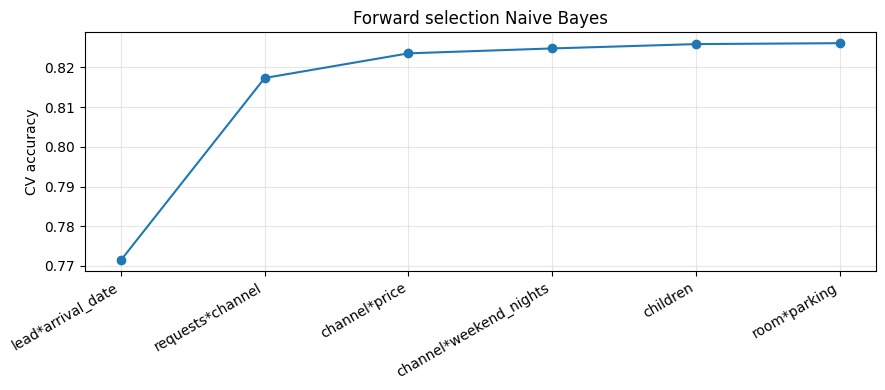

In [5]:
nb_folds = []
nb_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for tr_idx, va_idx in nb_skf.split(nb_X_train, nb_y_train):
    features = make_nb_features().fit(nb_X_train.iloc[tr_idx], nb_y_train[tr_idx])
    nb_folds.append((
        features.transform(nb_X_train.iloc[tr_idx]), nb_y_train[tr_idx],
        features.transform(nb_X_train.iloc[va_idx]), nb_y_train[va_idx],
    ))


def cv_accuracy(columns, alpha=1.0):
    scores = []
    for X_a, y_a, X_b, y_b in nb_folds:
        model = NaiveBayes(categorical_features=range(len(columns)), alpha=alpha)
        model.fit(X_a[columns].values, y_a)
        scores.append(accuracy_score(y_b, model.predict(X_b[columns].values)))
    return float(np.mean(scores))


print(f'Semua fitur tunggal tanpa seleksi -> CV accuracy = {cv_accuracy(list(nb_X.columns)):.5f}')

nb_candidates = list(nb_folds[0][0].columns)
nb_features = []
nb_history = []
nb_best_score = 0.0
start = time.time()
while len(nb_features) < 10:
    scores = [(cv_accuracy(nb_features + [c]), c) for c in nb_candidates if c not in nb_features]
    score, feature = max(scores)
    if score <= nb_best_score:
        break
    nb_features.append(feature)
    nb_history.append(score)
    nb_best_score = score
    print(f'+ {feature:28s} CV accuracy = {score:.5f}  ({time.time() - start:.0f} s)')

print(f'\nFitur terpilih: {nb_features}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(nb_history) + 1), nb_history, marker='o')
plt.xticks(range(1, len(nb_history) + 1), nb_features, rotation=30, ha='right')
plt.ylabel('CV accuracy')
plt.title('Forward selection Naive Bayes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Tuning Laplace smoothing $\alpha$

In [6]:
nb_alpha_scores = {alpha: cv_accuracy(nb_features, alpha) for alpha in [0.5, 1, 2]}
for alpha, score in nb_alpha_scores.items():
    print(f'alpha = {alpha:<4} -> CV accuracy = {score:.5f}')
nb_alpha = max(nb_alpha_scores, key=nb_alpha_scores.get)
print(f'alpha terpilih: {nb_alpha}')

alpha = 0.5  -> CV accuracy = 0.82533
alpha = 1    -> CV accuracy = 0.82610
alpha = 2    -> CV accuracy = 0.82583
alpha terpilih: 1


#### Perbandingan dengan scikit-learn

Pembanding yang setara adalah `CategoricalNB` pada fitur yang sama. `CategoricalNB` butuh kode integer, jadi fitur di-encode dengan `OrdinalEncoder`, dan nilai yang tidak muncul di train diberi kode kategori tambahan (setara slot "unseen" pada implementasi scratch).

                       Model  Accuracy  Precision  Recall  F1 (Canceled=1)  Macro F1
       Naive Bayes (scratch)  0.822831   0.730168 0.72854         0.729353  0.798833
CategoricalNB (scikit-learn)  0.822831   0.730168 0.72854         0.729353  0.798833

Prediction agreement: 100.00%

--- Classification Report: Naive Bayes (scratch) ---
              precision    recall  f1-score   support

           0     0.8678    0.8688    0.8683      3681
           1     0.7302    0.7285    0.7294      1794

    accuracy                         0.8228      5475
   macro avg     0.7990    0.7987    0.7988      5475
weighted avg     0.8227    0.8228    0.8228      5475



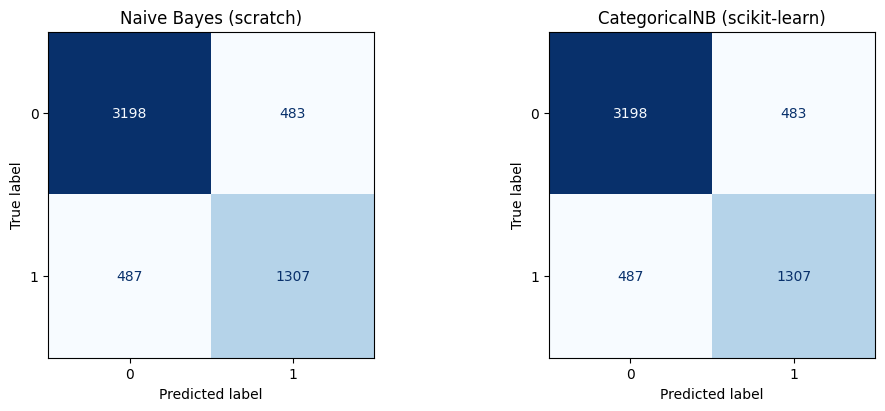

In [7]:
nb_preprocess = make_nb_features().fit(nb_X_train, nb_y_train)
nb_A = nb_preprocess.transform(nb_X_train)[nb_features]
nb_B = nb_preprocess.transform(nb_X_val)[nb_features]

nb_model = NaiveBayes(categorical_features=range(len(nb_features)), alpha=nb_alpha)
nb_model.fit(nb_A.values, nb_y_train)
nb_val_pred = nb_model.predict(nb_B.values)

nb_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
sk_A = nb_encoder.fit_transform(nb_A.astype(str))
sk_B = nb_encoder.transform(nb_B.astype(str))
n_categories = np.array([len(c) for c in nb_encoder.categories_])
sk_B = np.where(sk_B < 0, n_categories, sk_B)

sk_nb = CategoricalNB(alpha=nb_alpha, min_categories=n_categories + 1).fit(sk_A, nb_y_train)
sk_val_pred = sk_nb.predict(sk_B)


def nb_metrics(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 (Canceled=1)': f1_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
    }


nb_comparison = pd.DataFrame([
    nb_metrics('Naive Bayes (scratch)', nb_y_val, nb_val_pred),
    nb_metrics('CategoricalNB (scikit-learn)', nb_y_val, sk_val_pred),
])
print(nb_comparison.to_string(index=False))
print(f'\nPrediction agreement: {(nb_val_pred == sk_val_pred).mean() * 100:.2f}%')

print('\n--- Classification Report: Naive Bayes (scratch) ---')
print(classification_report(nb_y_val, nb_val_pred, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for ax, (name, pred) in zip(axes, [('Naive Bayes (scratch)', nb_val_pred), ('CategoricalNB (scikit-learn)', sk_val_pred)]):
    ConfusionMatrixDisplay.from_predictions(nb_y_val, pred, labels=[0, 1], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.show()

#### Bonus: graf Naive Bayes

Graf di bawah menunjukkan struktur model: variabel kelas `is_canceled` menjadi parent dari setiap atribut yang dipakai model (asumsi independensi bersyarat), dengan tebal edge sebanding dengan mutual information $I(X_j; C)$ yang dihitung dari tabel probabilitas model. Atribut gabungan dihubungkan (garis putus-putus) ke fitur asalnya untuk menunjukkan dependensi antarfitur yang ditangkap.

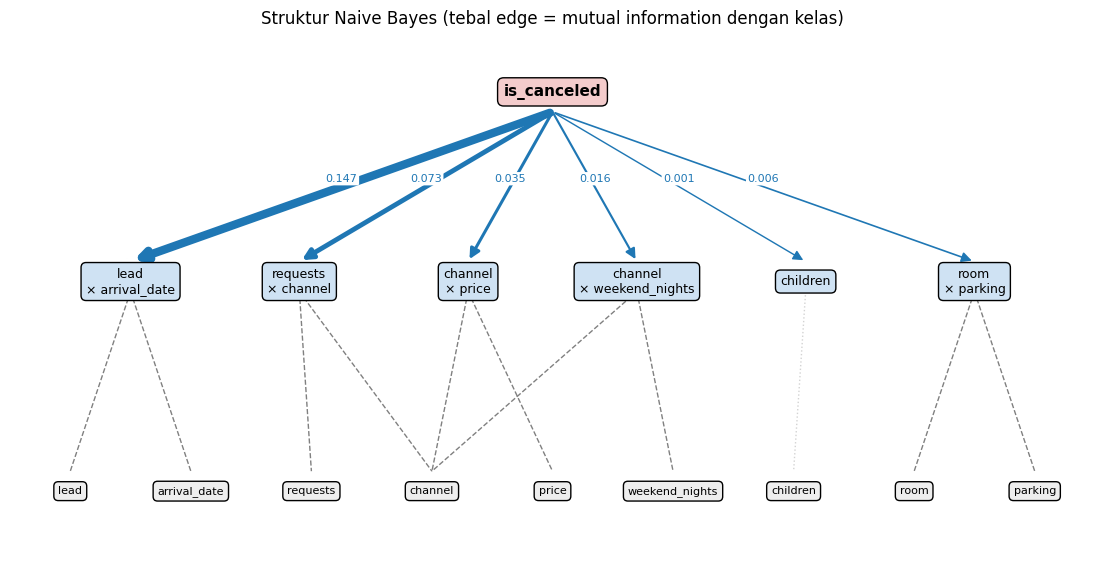

In [8]:
def nb_mutual_information(model, j):
    prior = np.exp(model.class_log_prior_)[:, None]
    conditional = np.exp(model.feature_log_prob_[j])
    joint = prior * conditional
    marginal = joint.sum(axis=0, keepdims=True)
    return float(np.sum(joint * np.log(conditional / marginal)))


def draw_nb_graph(model, features, path):
    mi = [nb_mutual_information(model, j) for j in range(len(features))]
    base = []
    for f in features:
        for part in f.split('*'):
            if part not in base:
                base.append(part)

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.axis('off')
    ax.set_xlim(-0.5, max(len(features), len(base)) - 0.5)
    ax.set_ylim(-0.3, 2.4)
    center = (max(len(features), len(base)) - 1) / 2
    attr_x = np.linspace(center - (len(features) - 1) / 2 * 1.4, center + (len(features) - 1) / 2 * 1.4, len(features))
    base_x = np.linspace(center - (len(base) - 1) / 2, center + (len(base) - 1) / 2, len(base))
    box = dict(boxstyle='round,pad=0.4', ec='black')

    for x, f, m in zip(attr_x, features, mi):
        ax.annotate('', xy=(x, 1.25), xytext=(center, 2.0),
                    arrowprops=dict(arrowstyle='-|>', lw=1 + 5 * m / max(mi), mutation_scale=15, color='tab:blue'))
        ax.text((x + center) / 2, 1.65, f'{m:.3f}', fontsize=8, ha='center', color='tab:blue',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
        if '*' in f:
            for part in f.split('*'):
                ax.plot([x, base_x[base.index(part)]], [1.1, 0.2], ls='--', color='gray', lw=1)
        else:
            ax.plot([x, base_x[base.index(f)]], [1.1, 0.2], ls=':', color='lightgray', lw=1)
        ax.text(x, 1.15, f.replace('*', '\n× '), ha='center', va='center', fontsize=9, bbox={**box, 'fc': '#cfe2f3'})
    for x, f in zip(base_x, base):
        ax.text(x, 0.1, f, ha='center', va='center', fontsize=8, bbox={**box, 'fc': '#eeeeee'})
    ax.text(center, 2.1, 'is_canceled', ha='center', va='center', fontsize=11, fontweight='bold', bbox={**box, 'fc': '#f4cccc'})
    ax.set_title('Struktur Naive Bayes (tebal edge = mutual information dengan kelas)')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


Path('output').mkdir(exist_ok=True)
draw_nb_graph(nb_model, nb_features, 'output/naive_bayes_graph.png')

### Bonus optimasi: Weighted Naive Bayes

Forward selection di atas berhenti di sedikit fitur karena NB tidak bisa menangani fitur redundan. **Weighted Naive Bayes** (WANBIA, Zaidi et al., 2013) mengatasinya dengan memberi bobot pada setiap fitur:

$$\log \frac{P(c=1 \mid x)}{P(c=0 \mid x)} = b + \sum_j w_j \log \frac{P(x_j \mid c=1)}{P(x_j \mid c=0)}$$

- Tabel $P(x_j \mid c)$ tetap dihitung dengan cara Naive Bayes biasa (frekuensi + Laplace smoothing).
- Bobot $w_j$ dan bias $b$ dipelajari dengan meminimalkan log-loss (Newton's method + regularisasi L2). Fitur yang redundan otomatis mendapat bobot kecil, sehingga model dapat memakai ribuan fitur gabungan sekaligus.
- Agar bobot tidak terlalu percaya pada fitur jarang, rasio likelihood untuk melatih bobot dihitung secara *out-of-fold* (tabel dari 5 fold lain).

Fitur yang dipakai (`WideFeatures`): fitur tunggal (bin MDL, kuantil 10 dan 40, penanda missing), semua pasangan dua fitur, gabungan tiga fitur dari 16 fitur utama, dan gabungan empat fitur dari 8 fitur utama. Hyperparameter ($\alpha$ = 0.3, L2 = 10) dipilih lewat cross-validation di `experiments/naive_bayes/run_weighted.py`.

Referensi: Zaidi, N. A., Cerquides, J., Carman, M. J., & Webb, G. I. (2013). *Alleviating Naive Bayes Attribute Independence Assumption by Attribute Weighting*. JMLR 14, 1947–1988.

In [9]:
import warnings

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)

wnb_alpha = 0.3
wnb_l2 = 10
wnb_inner_folds = 5
wnb_triples = TRIPLE_BASE[:16]
wnb_quads = QUAD_BASE[:8]


def make_wide_features():
    return WideFeatures(triples=wnb_triples, quads=wnb_quads)


def make_wnb(n_features):
    return WeightedNaiveBayes(
        categorical_features=range(n_features), alpha=wnb_alpha, l2=wnb_l2,
        n_folds=wnb_inner_folds, random_state=RANDOM_STATE,
    )


wnb_X = prepare_nb_features(train_df, extra=True, flags=True)
wnb_X_train, wnb_X_val = wnb_X.loc[nb_X_train.index], wnb_X.loc[nb_X_val.index]

start = time.time()
wnb_preprocess = make_wide_features().fit(wnb_X_train, nb_y_train)
wnb_A = wnb_preprocess.transform(wnb_X_train)
wnb_B = wnb_preprocess.transform(wnb_X_val)
print(f'Jumlah fitur WideFeatures: {wnb_A.shape[1]}')

wide_plain = NaiveBayes(categorical_features=range(wnb_A.shape[1]), alpha=wnb_alpha)
wide_plain.fit(wnb_A.values, nb_y_train)
wide_plain_pred = wide_plain.predict(wnb_B.values)

wnb_model = make_wnb(wnb_A.shape[1]).fit(wnb_A.values, nb_y_train)
wnb_val_pred = wnb_model.predict(wnb_B.values)
print(f'Waktu training + prediksi: {time.time() - start:.0f} s')

wnb_comparison = pd.DataFrame([
    nb_metrics('Naive Bayes, fitur terpilih', nb_y_val, nb_val_pred),
    nb_metrics('Naive Bayes, semua WideFeatures', nb_y_val, wide_plain_pred),
    nb_metrics('Weighted Naive Bayes, semua WideFeatures', nb_y_val, wnb_val_pred),
])
print(wnb_comparison.to_string(index=False))
print('\n--- Classification Report: Weighted Naive Bayes ---')
print(classification_report(nb_y_val, wnb_val_pred, digits=4))

Jumlah fitur WideFeatures: 1239


Waktu training + prediksi: 28 s
                                   Model  Accuracy  Precision   Recall  F1 (Canceled=1)  Macro F1
             Naive Bayes, fitur terpilih  0.822831   0.730168 0.728540         0.729353  0.798833
         Naive Bayes, semua WideFeatures  0.770046   0.611598 0.817168         0.699594  0.756662
Weighted Naive Bayes, semua WideFeatures  0.861370   0.800000 0.769231         0.784314  0.841087

--- Classification Report: Weighted Naive Bayes ---
              precision    recall  f1-score   support

           0     0.8896    0.9063    0.8979      3681
           1     0.8000    0.7692    0.7843      1794

    accuracy                         0.8614      5475
   macro avg     0.8448    0.8378    0.8411      5475
weighted avg     0.8602    0.8614    0.8607      5475



> Dengan fitur yang sama, NB biasa justru turun drastis karena ribuan fitur yang saling berkorelasi dikalikan seolah-olah independen. Pemberian bobot menghilangkan masalah ini sehingga fitur gabungan berorde tinggi bisa dimanfaatkan.

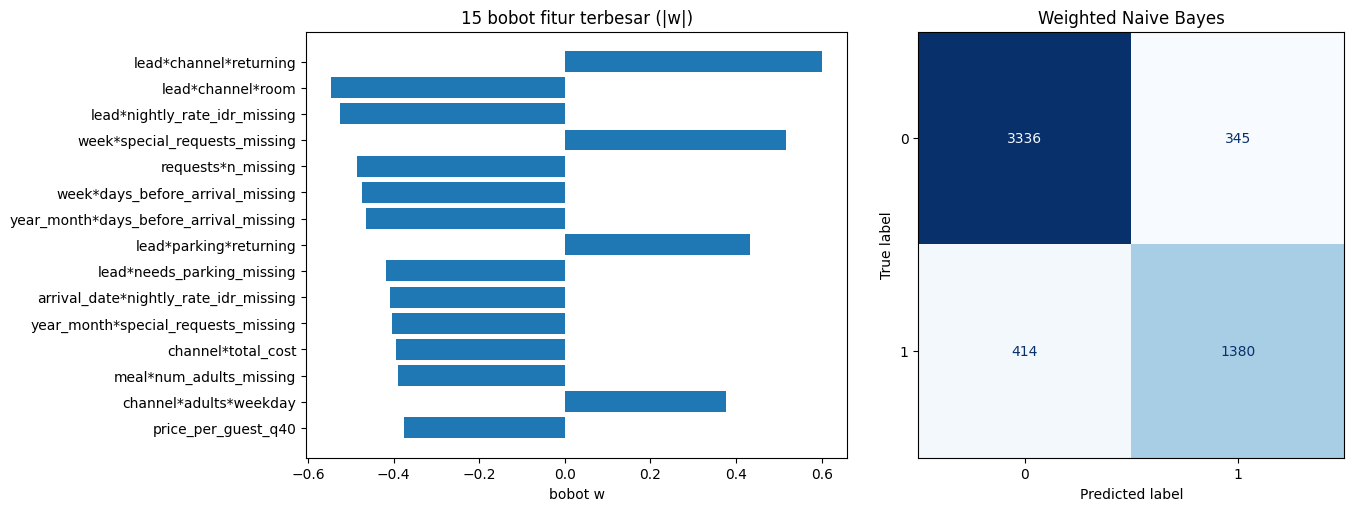

Bobot rata-rata: -0.0006 | bobot = 1 berarti sama dengan NB biasa


In [10]:
wnb_names = np.array(wnb_A.columns)
order = np.argsort(-np.abs(wnb_model.weights_))[:15]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
axes[0].barh(wnb_names[order][::-1], wnb_model.weights_[order][::-1], color='tab:blue')
axes[0].set_title('15 bobot fitur terbesar (|w|)')
axes[0].set_xlabel('bobot w')
ConfusionMatrixDisplay.from_predictions(nb_y_val, wnb_val_pred, labels=[0, 1], ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Weighted Naive Bayes')
plt.show()

print(f'Bobot rata-rata: {wnb_model.weights_.mean():.4f} | bobot = 1 berarti sama dengan NB biasa')
del wnb_A, wnb_B, wide_plain

## Submission

Dua submisi dibuat: Naive Bayes biasa (`submission_naive_bayes.csv`) dan Weighted Naive Bayes (`submission_wnb.csv`). Keduanya dilatih ulang pada seluruh data train, disimpan, lalu di-load kembali untuk memastikan prediksinya identik.

In [11]:
Path('output').mkdir(exist_ok=True)
nb_test_X = prepare_nb_features(test_df)

nb_final_preprocess = make_nb_features().fit(nb_X, nb_y)
nb_final = NaiveBayes(categorical_features=range(len(nb_features)), alpha=nb_alpha)
nb_final.fit(nb_final_preprocess.transform(nb_X)[nb_features].values, nb_y)
nb_X_test = nb_final_preprocess.transform(nb_test_X)[nb_features]

nb_model_path = 'output/naive_bayes.pkl'
nb_final.save(nb_model_path)
nb_loaded = NaiveBayes.load(nb_model_path)
nb_test_pred = nb_loaded.predict(nb_X_test.values)
np.testing.assert_array_equal(nb_final.predict(nb_X_test.values), nb_test_pred)


def save_submission(pred, path):
    submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': pred.astype(int)})
    assert len(submission) == len(sample_submission)
    assert list(submission.columns) == list(sample_submission.columns)
    assert submission['is_canceled'].isin([0, 1]).all()
    submission.to_csv(path, index=False)
    print(f"{len(submission)} prediksi tersimpan di '{path}': {submission['is_canceled'].value_counts().to_dict()}")
    return submission


nb_submission = save_submission(nb_test_pred, 'output/submission_naive_bayes.csv')
nb_submission.head()

6844 prediksi tersimpan di 'output/submission_naive_bayes.csv': {0: 4706, 1: 2138}


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [12]:
start = time.time()
wnb_final_preprocess = make_wide_features().fit(wnb_X, nb_y)
wnb_full = wnb_final_preprocess.transform(wnb_X)
wnb_final = make_wnb(wnb_full.shape[1]).fit(wnb_full.values, nb_y)
del wnb_full
wnb_X_test = wnb_final_preprocess.transform(prepare_nb_features(test_df, extra=True, flags=True))

wnb_model_path = 'output/weighted_naive_bayes.pkl'
wnb_final.save(wnb_model_path)
wnb_loaded = WeightedNaiveBayes.load(wnb_model_path)
wnb_test_pred = wnb_loaded.predict(wnb_X_test.values)
np.testing.assert_array_equal(wnb_final.predict(wnb_X_test.values), wnb_test_pred)
print(f'Training final + prediksi: {time.time() - start:.0f} s')

wnb_submission = save_submission(wnb_test_pred, 'output/submission_wnb.csv')
wnb_submission.head()

Training final + prediksi: 40 s
6844 prediksi tersimpan di 'output/submission_wnb.csv': {0: 4777, 1: 2067}


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0
